In [67]:
import torch
import torch.nn as nn
from typing import Union

from torch.utils.data import DataLoader
from torchmetrics.classification import Accuracy
from torchmetrics import ConfusionMatrix
from torchvision import datasets, transforms
import torchvision.models as models
from torchsummary import summary
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np




### 1. Comparaison de réseaux.

1. Chargement et prétraitement des données CIFAR100.
2.

In [42]:
train = datasets.CIFAR100(
    root="./data",
    train=True,
    download=True,
    transform=transforms.ToTensor(),
)

test = datasets.CIFAR100(
    root="./data",
    download=True,
    train=False,
    transform=transforms.ToTensor(),
)

Nombre d'image du jeu de données: 60000
Dimensions d'une image: torch.Size([3, 32, 32])
Nombre de labels uniques dans le jeu d'entrainement 100
Nombre de labels uniques dans le jeu de test 100
Image 1 label: 19


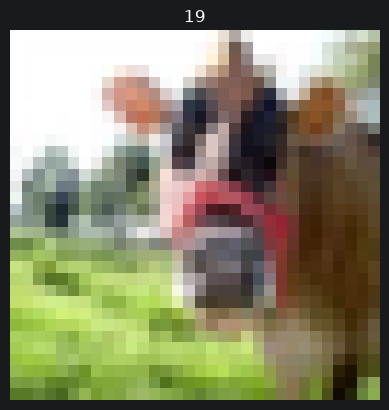

Image 2 label: 29


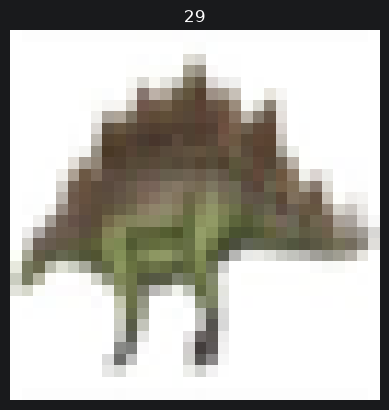

Image 3 label: 0


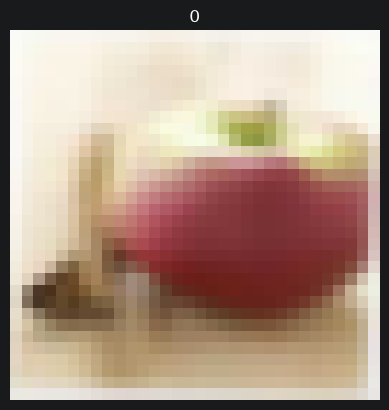

Image 4 label: 11


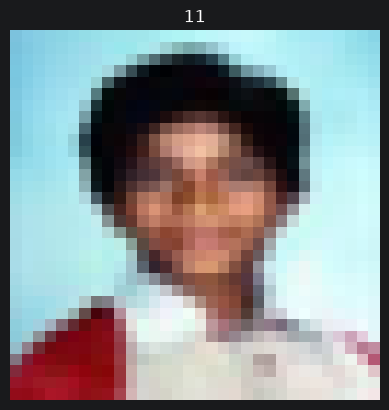

Image 5 label: 1


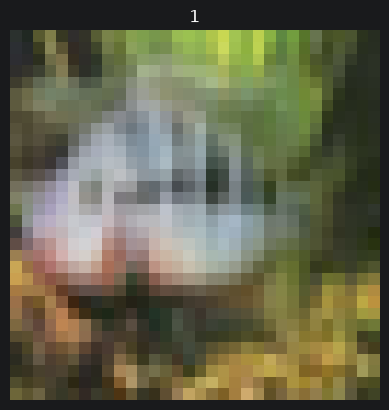

In [43]:
print(f"Nombre d'image du jeu de données: {len(train) + len(validation)}")
image, label = train[0]
print(f"Dimensions d'une image: {image.shape}")


print(f"Nombre de labels uniques dans le jeu d'entrainement {len(np.unique(train.targets))}")
print(f"Nombre de labels uniques dans le jeu de test {len(np.unique(test.targets))}")


for i in range(5):
    image, label = train[i]
    print(f"Image {i+1} label: {label}")
    plt.imshow(image.permute(1, 2, 0))
    plt.title(str(label))
    plt.axis('off')
    plt.show()

### 2. Melange du jeu de données et récuperation d 10% du jeu de données initial

In [44]:
from torch.utils.data import Subset

torch.manual_seed(42)

_, partial_indices = train_test_split(
    range(len(train)),
    test_size=0.1,
    stratify=train.targets,
    random_state=42
)
partial_train= Subset(train, partial_indices)


In [45]:

partial_train_labels = [train.targets[indice] for indice in partial_train.indices]
partial_train_indices, partial_validation_indice = train_test_split(
    range(len(partial_train)),
    test_size=0.2,
    stratify=partial_train_labels,
    random_state=42
)

partial_validation = Subset(partial_train, partial_validation_indice)
partial_train = Subset(partial_train, partial_train_indices)


print(f"Nombre d'images du jeu de données contient {len(partial_train)} images")
partial_train_labels = [train.targets[indice] for indice in partial_train.indices]
print(f"Nombres de labels différents du jeu de données: {len(np.unique(partial_train_labels))}")

Nombre d'images du jeu de données contient 4000 images
Nombres de labels différents du jeu de données: 100


### 3. Entrainement et évaluation de CIFAR100 avec le réseau du TD1 (1 couche convolutionnelle de noyau 5x5, padding= "same" et un MaxPool K=2 S=2)

In [58]:
class ConvolutionBlock(nn.Module):

    def __init__(self, input_shape: tuple, n_filters: int, kernel_size: int, padding: Union[str, int] = "same", stride: int = 1, use_batch_norm: bool = False, use_pooling: bool = True, pool_kernel_size: int = 2, pool_stride: int = 2, pool_padding: int = 0, dropout_rate: float = 0.0 ):

        super().__init__()

        self.input_shape = input_shape
        self.n_filters = n_filters
        self.kernel_size = kernel_size
        self.conv_padding = padding
        self.conv_stride = stride
        self.pooling_kernel_size = pool_kernel_size
        self.pooling_stride = pool_stride
        self.pooling_padding = pool_padding

        self.conv = nn.Conv2d(
            in_channels= input_shape[0],
            out_channels= n_filters,
            kernel_size=kernel_size,
            padding=padding,
            stride=stride,
        )

        self.batch_norm = nn.BatchNorm2d(
            num_features=n_filters,
        ) if use_batch_norm else None

        self.activation = nn.ReLU()
        self.dropout = nn.Dropout(p=dropout_rate)
        self.pool = nn.MaxPool2d(
            kernel_size=pool_kernel_size,
            stride=pool_stride,
            padding=pool_padding,
        ) if use_pooling else None


    def forward(self, X) :
        output = self.conv(X)
        if self.batch_norm is not None:
            output = self.batch_norm(output)
        output = self.activation(output)
        if self.pool is not None:
            output = self.pool(output)
        return self.dropout(output)


    def output_shape(self):
        height = self.input_shape[1]
        width = self.input_shape[2]

        if self.conv_padding == "same":
            height_before_pooling = height
            width_before_pooling = width
        else:
            assert isinstance(self.conv_padding, int)
            height_before_pooling =  (height - self.kernel_size + 2 * self.conv_padding) // self.conv_stride + 1
            width_before_pooling = (width - self.kernel_size + 2 * self.conv_padding) // self.conv_stride + 1

        if not self.pool:
              height_after_pooling = height_before_pooling
              width_after_pooling  = width_before_pooling
        else:
            height_after_pooling: int = (height_before_pooling - self.pooling_kernel_size + 2 * self.pooling_padding) // self.pooling_stride + 1
            width_after_pooling: int = (width_before_pooling - self.pooling_kernel_size + 2 * self.pooling_padding) // self.pooling_stride + 1

        return self.n_filters, height_after_pooling, width_after_pooling

    def n_pixels(self) -> int:
        shape = self.output_shape()
        return shape[0] * shape[1] * shape[2]



class ExperimentalCNN(nn.Module):
    def __init__(self, convolutions: nn.ModuleList, n_neural_layer: int, n_labels: int , learning_rate: float):
        super().__init__()

        self.conv_blocks = convolutions
        self.n_labels = n_labels

        # Historique de la loss
        self.losses = []
        self.epoch_boundaries = []

        # Historique de la validation (mesurée tous les N batchs)
        self.validation_steps = []
        self.validation_losses = []
        self.validation_accuracies = []
        self.mean_loss_per_step = []

        self.flatten = nn.Flatten()
        self.linear = nn.Linear(
            in_features=self.conv_blocks[-1].n_pixels(),
            out_features=n_neural_layer,
        )
        self.out_layer = nn.Linear(
            in_features=n_neural_layer,
            out_features=n_labels,
        )
        self.activation = nn.ReLU()


        self.loss_function = nn.CrossEntropyLoss()
        self.optimizer = torch.optim.Adam(
            params=self.parameters(),
            lr=learning_rate,
        )

    def forward(self, X):
        for convolution in self.conv_blocks:
            X = convolution(X)
        output = self.flatten(X)
        output = self.linear(output)
        output = self.activation(output)
        return self.out_layer(output)


    def _validation_metrics(self, validation, batch_size):
        loader = DataLoader(
            dataset=validation,
            batch_size=batch_size,
            shuffle=False
        )

        self.eval()
        total_loss = 0.0
        correct = 0

        with torch.no_grad():
            for X_batch, y_batch in loader:
                output = self(X_batch)
                total_loss += self.loss_function(output, y_batch).item() * len(y_batch)
                correct += (output.argmax(dim=1) == y_batch).sum().item()

        self.train()
        return total_loss / len(validation), correct / len(validation)


    def fit(self, train_data, epochs, batch_size, validation_data=None, eval_every=100):
        train_batch = DataLoader(
            dataset=train_data,
            batch_size=batch_size,
            shuffle=True
        )

        self.train()
        step = 0

        for epoch in range(epochs):
            for X_batch, y_batch in train_batch:
                self.optimizer.zero_grad()
                loss = self.loss_function(self(X_batch), y_batch)
                loss.backward()
                self.optimizer.step()

                # On conserve la loss de chaque batch
                self.losses.append(loss.item())
                step += 1

                # Contrôle sur la validation tous les eval_every steps
                if validation_data is not None and step % eval_every == 0:
                    self.mean_loss_per_step.append(sum(self.losses[-eval_every:]) / eval_every)
                    validation_loss, validation_acc = self._validation_metrics(validation_data, batch_size)
                    self.validation_steps.append(step)
                    self.validation_losses.append(validation_loss)
                    self.validation_accuracies.append(validation_acc)

            # Position du passage à l'époque suivante
            if epoch < epochs - 1:
                self.epoch_boundaries.append(len(self.losses))


    def evaluate(self, data, batch_size):
        loader = DataLoader(
            dataset=data,
            batch_size=batch_size,
            shuffle=False
        )
        y_pred, y_true, probas = [], [], []
        self.eval()
        with torch.no_grad():
            for X, y in loader:
                out = self(X)
                y_pred.append(out.argmax(dim=1))
                y_true.append(y)
                probas.append(torch.softmax(out, dim=1))
        return torch.cat(y_pred), torch.cat(y_true), torch.cat(probas)


    def plot_loss(self, show_validation=True):
        plt.figure(figsize=(10, 5))

        if show_validation and self.validation_losses:
            plt.plot(self.validation_steps, self.mean_loss_per_step, "o-", label="Train (moyenne)")
            plt.plot(self.validation_steps, self.validation_losses, "o-", label="Validation")
        else:
            plt.plot(range(1, len(self.losses) + 1), self.losses, label="Train")

        for boundary in self.epoch_boundaries:
            plt.axvline(x=boundary, linestyle="--", color="gray", alpha=0.5)

        plt.xlabel("Step (batch)")
        plt.ylabel("Loss")
        plt.title("Évolution de la loss pendant l'entraînement")
        plt.legend()
        plt.show()


    def plot_accuracy(self):
        plt.figure(figsize=(10, 5))
        plt.plot(self.validation_steps, self.validation_accuracies, "o-", label="Validation")

        for boundary in self.epoch_boundaries:
            plt.axvline(x=boundary, linestyle="--", color="gray", alpha=0.5)

        plt.xlabel("Step (batch)")
        plt.ylabel("Accuracy")
        plt.title("Évolution de l'accuracy sur la validation")
        plt.legend()
        plt.show()


    def score(self, data, batch_size, scoring="accuracy"):
        y_pred, y_true, _ = self.evaluate(data, batch_size)

        match scoring:
            case "accuracy":
                metric = Accuracy(task="multiclass", num_classes=self.n_labels)
                return metric(y_pred, y_true).item()

            case "confusion_matrix":
                metric = ConfusionMatrix(task="multiclass", num_classes=self.n_labels)
                matrix = metric(y_pred, y_true)

                plt.figure(figsize=(8, 6))
                sns.heatmap(matrix.numpy(), annot=True, fmt="d", cmap="Blues")
                plt.xlabel("Prédiction")
                plt.ylabel("Vrai label")
                plt.title("Matrice de confusion")
                plt.show()
                return matrix

        raise ValueError(f"Métrique inconnue : {scoring}")


    def show_summary(self):
        summary(self, input_size=self.conv_blocks[0].input_shape)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 10, 32, 32]             760
              ReLU-2           [-1, 10, 32, 32]               0
         MaxPool2d-3           [-1, 10, 16, 16]               0
           Dropout-4           [-1, 10, 16, 16]               0
  ConvolutionBlock-5           [-1, 10, 16, 16]               0
           Flatten-6                 [-1, 2560]               0
            Linear-7                  [-1, 300]         768,300
              ReLU-8                  [-1, 300]               0
            Linear-9                  [-1, 100]          30,100
Total params: 799,160
Trainable params: 799,160
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.01
Forward/backward pass size (MB): 0.24
Params size (MB): 3.05
Estimated Total Size (MB): 3.30
-------------------------------------------

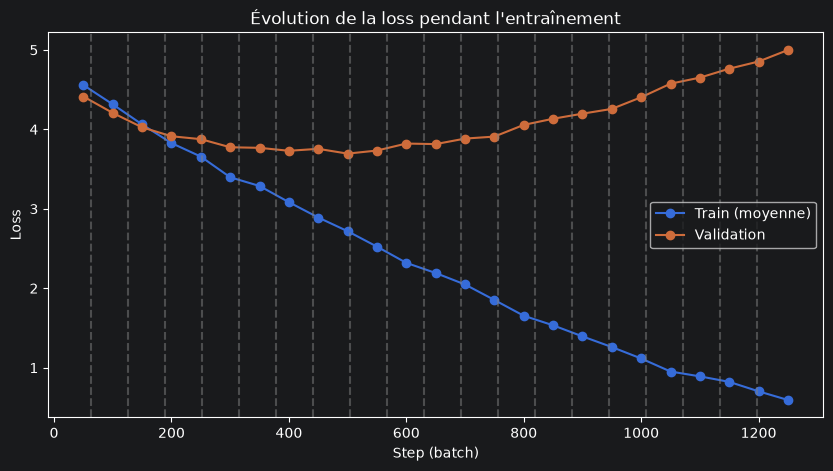

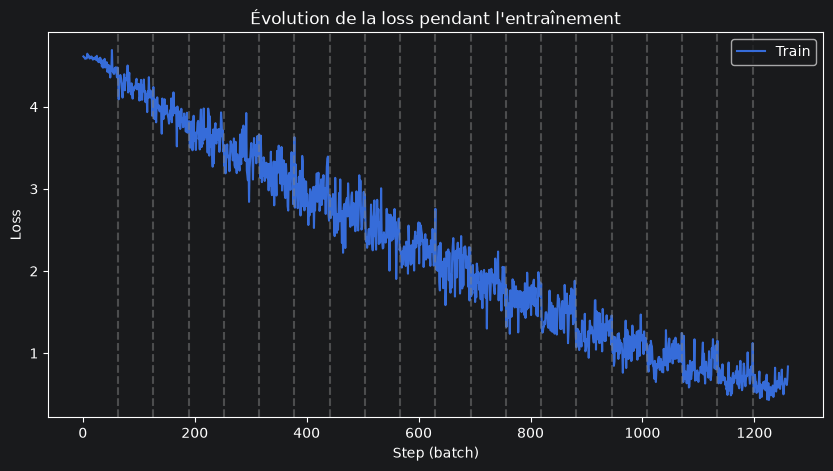

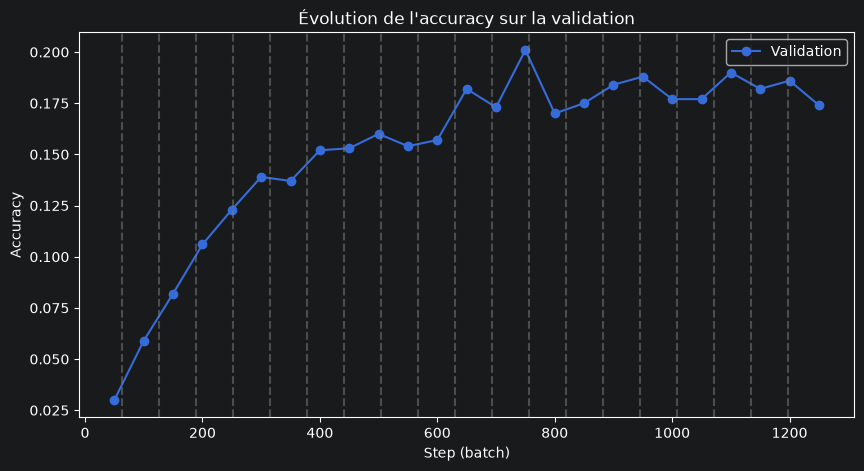

La précision de l'expérience 1 est de:  0.16979999840259552


In [48]:
# Construction des expérimentations

conv_bloc = ConvolutionBlock(
    input_shape=(3, 32, 32),
    n_filters=10,
    kernel_size=5,
)

classical_cnn = ExperimentalCNN(
    convolutions=nn.ModuleList([conv_bloc]),
    n_neural_layer=300,
    n_labels=len(np.unique(partial_train_labels)),
    learning_rate=1e-3
)

classical_cnn.show_summary()
classical_cnn.fit(
    train_data=partial_train,
    epochs=20,
    batch_size=64,
    validation_data=partial_validation,
    eval_every=50
)
classical_cnn.plot_loss()
classical_cnn.plot_loss(show_validation=False)
classical_cnn.plot_accuracy()
print(f"La précision de l'expérience 1 est de: ", classical_cnn.score(test, batch_size=65, scoring="accuracy"))


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 96, 32, 32]          14,208
       BatchNorm2d-2           [-1, 96, 32, 32]             192
              ReLU-3           [-1, 96, 32, 32]               0
         MaxPool2d-4           [-1, 96, 15, 15]               0
           Dropout-5           [-1, 96, 15, 15]               0
  ConvolutionBlock-6           [-1, 96, 15, 15]               0
            Conv2d-7          [-1, 256, 15, 15]         614,656
       BatchNorm2d-8          [-1, 256, 15, 15]             512
              ReLU-9          [-1, 256, 15, 15]               0
        MaxPool2d-10            [-1, 256, 7, 7]               0
          Dropout-11            [-1, 256, 7, 7]               0
 ConvolutionBlock-12            [-1, 256, 7, 7]               0
           Conv2d-13            [-1, 384, 7, 7]         885,120
      BatchNorm2d-14            [-1, 38

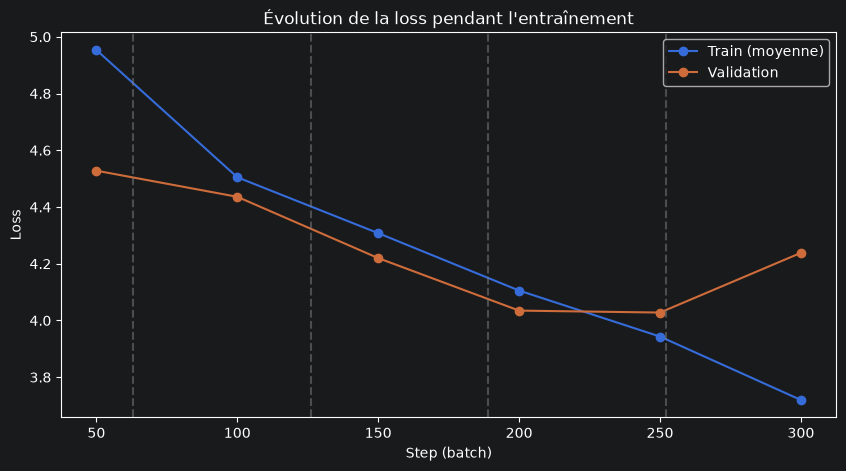

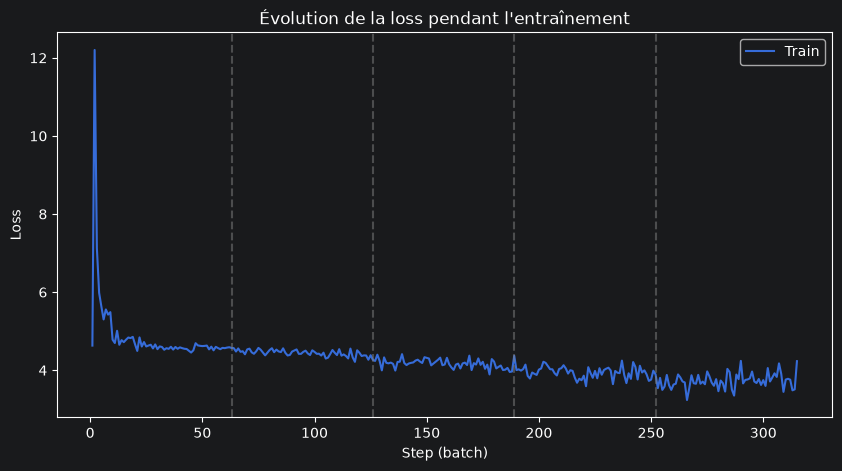

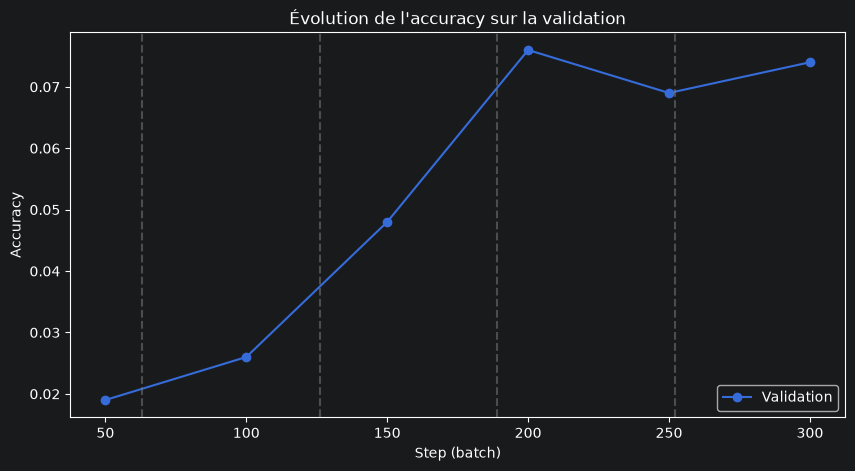

La précision de l'expérience 1 est de:  0.10599999874830246


In [61]:
conv_bloc_1 = ConvolutionBlock(
    input_shape=(3, 32, 32),
    n_filters=96,
    kernel_size=7,
    stride=1,
    padding="same",
    pool_kernel_size=3,
    pool_stride=2,
    dropout_rate=0.2,
    use_batch_norm=True,
)
conv_bloc_2 = ConvolutionBlock(
    input_shape=conv_bloc_1.output_shape(),
    n_filters=256,
    kernel_size=5,
    stride=1,
    padding="same",
    pool_kernel_size=3,
    pool_stride=2,
    dropout_rate=0.2,
    use_batch_norm=True,
)
conv_bloc_3 = ConvolutionBlock(
    input_shape=conv_bloc_2.output_shape(),
    n_filters=384,
    kernel_size=3,
    padding="same",
    use_pooling=False,
    dropout_rate=0.2,
    use_batch_norm=True,
)
conv_bloc_4 = ConvolutionBlock(
    input_shape=conv_bloc_3.output_shape(),
    n_filters=384,
    kernel_size=3,
    padding="same",
    use_pooling=False,
    dropout_rate=0.2,
    use_batch_norm=True,
)
conv_bloc_5 = ConvolutionBlock(
    input_shape=conv_bloc_4.output_shape(),
    n_filters=256,
    kernel_size=3,
    padding="same",
    pool_stride=2,
    dropout_rate=0.2,
    use_batch_norm=True,
)
alexNetModel = ExperimentalCNN(
    convolutions=nn.ModuleList([conv_bloc_1, conv_bloc_2, conv_bloc_3, conv_bloc_4, conv_bloc_5]),
    n_neural_layer=4096,
    n_labels=len(np.unique(partial_train_labels)),
    learning_rate=1e-3
)

alexNetModel.show_summary()
alexNetModel.fit(
    train_data=partial_train,
    epochs=5,
    batch_size=64,
    validation_data=partial_validation,
    eval_every=50
)
alexNetModel.plot_loss()
alexNetModel.plot_loss(show_validation=False)
alexNetModel.plot_accuracy()
print(f"La précision de l'expérience 1 est de: ", alexNetModel.score(test, batch_size=65, scoring="accuracy"))

### 4. Chargement d'un réseau ResNet18 pré entrainé sur CIFAR100

In [68]:
# Fine Tuning
def validation_metrics(model, loss_function, validation, batch_size):
        val_loader = DataLoader(
            dataset=validation,
            batch_size=batch_size,
            shuffle=False
        )

        model.eval()
        total_loss = 0.0
        correct = 0

        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                output = model(X_batch)
                total_loss += loss_function(output, y_batch).item() * len(y_batch)
                correct += (output.argmax(dim=1) == y_batch).sum().item()

        model.train()
        return total_loss / len(validation), correct / len(validation)



def train_resnet18(model, optimizer, loss_function, train_data, epochs, batch_size, validation_data=None, eval_every=100):
        train_batch = DataLoader(
            dataset=train_data,
            batch_size=batch_size,
            shuffle=True
        )


        losses = []
        epoch_boundaries = []
        mean_loss_per_step = []
        validation_steps = []
        validation_losses = []
        validation_accuracies = []


        model.train()
        step = 0

        for epoch in range(epochs):
            for X_batch, y_batch in train_batch:
                optimizer.zero_grad()
                loss = loss_function(model(X_batch), y_batch)
                loss.backward()
                optimizer.step()

                # On conserve la loss de chaque batch
                losses.append(loss.item())
                step += 1

                # Contrôle sur la validation tous les eval_every steps
                if validation_data is not None and step % eval_every == 0:
                    mean_loss_per_step.append(sum(losses[-eval_every:]) / eval_every)
                    validation_loss, validation_acc = validation_metrics(model, loss_function, validation_data, batch_size)
                    validation_steps.append(step)
                    validation_losses.append(validation_loss)
                    validation_accuracies.append(validation_acc)

            # Position du passage à l'époque suivante
            if epoch < epochs - 1:
                epoch_boundaries.append(len(losses))



        plt.figure(figsize=(10, 5))

        # Loss pendant l'entrainement et la validation
        if validation_data is not None and validation_losses:
            plt.plot(validation_steps, mean_loss_per_step, "o-", label="Train (moyenne)")
            plt.plot(validation_steps, validation_losses, "o-", label="Validation")
        else:
            plt.plot(range(1, len(losses) + 1), losses, label="Train")

        for boundary in epoch_boundaries:
            plt.axvline(x=boundary, linestyle="--", color="gray", alpha=0.5)

        plt.xlabel("Step (batch)")
        plt.ylabel("Loss")
        plt.title("Évolution de la loss pendant l'entraînement")
        plt.legend()
        plt.show()


        # Accuracy
        plt.plot(validation_steps, validation_accuracies, "o-", label="Validation")

        for boundary in epoch_boundaries:
            plt.axvline(x=boundary, linestyle="--", color="gray", alpha=0.5)

        plt.xlabel("Step (batch)")
        plt.ylabel("Accuracy")
        plt.title("Évolution de l'accuracy sur la validation")
        plt.legend()
        plt.show()



def evaluate(model, data, batch_size):
        loader = DataLoader(
            dataset=data,
            batch_size=batch_size,
            shuffle=False
        )
        y_pred, y_true, probas = [], [], []
        model.eval()
        with torch.no_grad():
            for X, y in loader:
                out = model(X)
                y_pred.append(out.argmax(dim=1))
                y_true.append(y)
                probas.append(torch.softmax(out, dim=1))
        return torch.cat(y_pred), torch.cat(y_true), torch.cat(probas)



def score(model, data, batch_size, scoring="accuracy"):
        y_pred, y_true, _ = evaluate(model, data, batch_size)

        match scoring:
            case "accuracy":
                metric = Accuracy(task="multiclass", num_classes=100)
                return metric(y_pred, y_true).item()

            case "confusion_matrix":
                metric = ConfusionMatrix(task="multiclass", num_classes=100)
                matrix = metric(y_pred, y_true)

                plt.figure(figsize=(8, 6))
                sns.heatmap(matrix.numpy(), annot=True, fmt="d", cmap="Blues")
                plt.xlabel("Prédiction")
                plt.ylabel("Vrai label")
                plt.title("Matrice de confusion")
                plt.show()
                return matrix

        raise ValueError(f"Métrique inconnue : {scoring}")



resNetModel = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)
resNetModel.fc = nn.Linear(
    in_features=resNetModel.fc.in_features,
    out_features=100
)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    params=resNetModel.parameters(),
    lr=1e-3
)



transform = models.ResNet18_Weights.DEFAULT.transforms()
resnet_data = datasets.CIFAR100(
    "./data",
    train=True,
    download=True,
    transform=transform,
)
resnet_test = datasets.CIFAR100(
    "./data",
    train=False,
    download=True,
    transform=transform,
)


train_resnet18(
    model=resNetModel,
    optimizer=optimizer,
    loss_function=loss_function,
    train_data=resnet_data,
    validation_data=resnet_test,
    epochs=5,
    batch_size=64,
)

print(f"L'accuracy pour resnet18 sur CIFAR100 est:  {score(
    model=resNetModel,
    data=resnet_test,
    batch_size=64,
)}")


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /home/thierry/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100.0%


KeyboardInterrupt: 

In [ ]:
# Feature Extraction
